In [2]:
import pandas as pd
import numpy as np

In [ ]:
samples = pd.read_csv("precise_mg1655-sample_table.csv", header=0)
tpm = pd.read_csv("precise_mg1655-log_tpm", header=0)
tpm_bin = pd.read_csv('MatrixM_binarized.csv', header=0)

In [4]:
tpm_bin.head()

,Unnamed: 0,Maltose,Crp,UC-3,Glycolate,RpoS,SG_1,SG_2,Translation,Fnr-2,...,SG_19,SG_20,UC-1,SG_21,FlhDC-1,Resistance,NtrC-2,ldrD,SG_22,SG_23
0,b0001,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,b0002,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,b0003,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,b0004,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,b0005,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
tpm.head()

,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430


In [5]:
samples.head()

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
0,pmg_wt_1,pan_fur,WT,1,pmg_wt_445;pmg_wt_446,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[object Object],[object Object]
1,pmg_wt_10,in_house_2,stationary,2,pmg_wt_3;pmg_wt_4,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,pmg_wt_100,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pmg_wt_101,single_nutrient_perturbation,Glucose_L-Ornithine,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pmg_wt_102,single_nutrient_perturbation,Glucose_L-Ornithine,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
def filter_tpm_by_metadata(filtered_metadata, tpm_table = tpm):
    """
    Filter TPM expression table using unique_identifier
    from a filtered metadata dataframe.

    Parameters
    ----------
    filtered_metadata : pd.DataFrame
        Filtered sample metadata containing unique_identifier.

    tpm_table : pd.DataFrame
        Gene expression table:
        rows = genes
        columns = sample unique_identifiers.

    Returns
    -------
    pd.DataFrame
        TPM table containing gene_id + selected samples.
    """

    # Get filtered sample IDs
    sample_ids = (filtered_metadata["unique_identifier"].tolist())

    # Keep only IDs that actually exist in TPM table
    valid_ids = [
        sample_id
        for sample_id in sample_ids
        if sample_id in tpm_table.columns
    ]

    # Check missing IDs
    missing_ids = [
        sample_id
        for sample_id in sample_ids
        if sample_id not in tpm_table.columns
    ]

    if missing_ids:
        print("Warning: IDs not found in TPM table:")
        print(missing_ids)

    # gene_id + selected samples
    filtered_tpm = tpm_table[["gene_id"] + valid_ids].copy()
    return filtered_tpm

In [186]:
# SNPv1
# C source variation, N source NH4Cl fixed
# condition: <C Source>_NH4Cl
# reference_condition_identifier: pmg_wt_77;pmg_wt_78

carbon_df = samples[
    (samples["project"] == "SNPv1")
    & (samples["condition"].str.endswith("_NH4Cl", na=False))
].copy()
carbon_df # 82 samples - 41 conditions, 2 replicates each

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
2,pmg_wt_100,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,pmg_wt_107,single_nutrient_perturbation,D-Trehalose_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,pmg_wt_108,single_nutrient_perturbation,D-Trehalose_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,pmg_wt_125,single_nutrient_perturbation,D-Mannose_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,pmg_wt_126,single_nutrient_perturbation,D-Mannose_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581,pmg_wt_95,single_nutrient_perturbation,D-Galactose_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
582,pmg_wt_96,single_nutrient_perturbation,D-Galactose_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
583,pmg_wt_97,single_nutrient_perturbation,Cytidine_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
584,pmg_wt_98,single_nutrient_perturbation,Cytidine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# e.g. the tpm table for carbon_df
carbon_tpm = filter_tpm_by_metadata(carbon_df, tpm)
carbon_tpm.head() # rows = genes, columns = 82 samples

,gene_id,pmg_wt_100,pmg_wt_107,pmg_wt_108,pmg_wt_125,pmg_wt_126,pmg_wt_141,pmg_wt_142,pmg_wt_143,pmg_wt_144,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,0.722802,1.090242,1.130414,1.860347,2.260856,-0.990012,-0.877302,1.217422,1.288113,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,-0.822170,-0.955810,-1.223776,-1.001151,-1.001738,-0.276547,-0.114908,-0.452704,-0.855671,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.091438,-0.803884,-1.207059,-0.791466,-0.815086,0.420163,0.490753,-0.188748,-0.720093,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.045651,-0.741174,-0.888425,-0.788650,-0.796482,0.267219,0.346992,-0.119051,-0.609777,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.470824,-0.298003,-0.370604,-0.683099,-0.937261,-0.473663,-1.197339,-0.562813,-0.627894,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430


In [ ]:
# e.g. the tpm table for carbon_df
carbon_tpm = filter_tpm_by_metadata(carbon_df, tpm_bin)
carbon_tpm.head() # rows = genes, columns = 82 samples

In [10]:
iModulons = pd.read_csv("MatrixM_binarized.csv", header=0)
modulon_dict = {
    modulon: set(iModulons.loc[iModulons[modulon] == 1, iModulons.columns[0]])
    for modulon in iModulons.columns[1:]
}  # iModulon: (genes)

gene_modulon_dict = {
    row[iModulons.columns[0]]: {
        modulon
        for modulon in iModulons.columns[1:]
        if row[modulon] == 1
    }
    for _, row in iModulons.iterrows()
    if row[iModulons.columns[1:]].sum() > 0
}# gene: (iMoludons it involves)

print (gene_modulon_dict)
print (modulon_dict)

{'b0001': {'Resistance'}, 'b0002': {'Leu/Val/Ile'}, 'b0003': {'Leu/Val/Ile'}, 'b0004': {'Leu/Val/Ile'}, 'b0005': {'UC-4'}, 'b0014': {'RpoH'}, 'b0015': {'RpoH'}, 'b0023': {'UC-9'}, 'b0031': {'Lysine/T2SS'}, 'b0032': {'Pyrimidine', 'Arginine'}, 'b0033': {'Pyrimidine', 'Arginine'}, 'b0034': {'Pyrimidine'}, 'b0042': {'Phosphate'}, 'b0057': {'UC-8'}, 'b0060': {'DNA Damage'}, 'b0061': {'Arabinose'}, 'b0062': {'Arabinose'}, 'b0063': {'Arabinose'}, 'b0068': {'Thiamine'}, 'b4662': {'Resistance', 'ldrD', 'Phosphate', 'Fucose'}, 'b0071': {'Leucine/Dipeptide', 'Lrp-2'}, 'b0072': {'Leucine/Dipeptide', 'Lrp-2'}, 'b0073': {'Leucine/Dipeptide', 'Lrp-2'}, 'b0074': {'Leucine/Dipeptide', 'Lrp-2'}, 'b0075': {'Resistance', 'Lrp-2'}, 'b0076': {'Lrp-2'}, 'b0084': {'Resistance'}, 'b0086': {'UC-5'}, 'b0112': {'TyrR'}, 'b0113': {'ArcA-2'}, 'b0114': {'SG_17', 'ArcA-2'}, 'b0115': {'ArcA-2'}, 'b0116': {'ArcA-2'}, 'b0118': {'ArcA-2'}, 'b0123': {'Copper'}, 'b0124': {'ArcA-2'}, 'b0132': {'UC-1'}, 'b0150': {'Fur-2'}, 

In [59]:
modulon_df=pd.DataFrame.from_dict(modulon_dict, orient='index').reset_index()
modulon_df.head()

,index,0,1,2,3,4,5,6,7,8,...,108,109,110,111,112,113,114,115,116,117
0,Maltose,b4034,b3571,b3417,b0403,b4033,b3416,b4032,b4035,b4036,...,None,None,None,None,None,None,None,None,None,None
1,Crp,b0723,b2094,b0651,b1891,b0727,b1819,b3364,b0721,b0728,...,None,None,None,None,None,None,None,None,None,None
2,UC-3,b1722,b3260,b3471,b2533,b2156,b2014,b4557,None,None,...,None,None,None,None,None,None,None,None,None,None
3,Glycolate,b2975,b4467,b2979,b4468,b2976,b2977,None,None,None,...,None,None,None,None,None,None,None,None,None,None
4,RpoS,b4755,b1847,b4045,b4126,b1955,b3555,b1684,b0707,b2131,...,b4149,b1051,b1678,b4743,b3153,b1536,b0789,b4411,b0897,b2266


In [60]:
modulon_df_T = modulon_df.T
modulon_df_T.head()

,0,1,2,3,4,5,6,7,8,9,...,105,106,107,108,109,110,111,112,113,114
index,Maltose,Crp,UC-3,Glycolate,RpoS,SG_1,SG_2,Translation,Fnr-2,DNA Damage,...,SG_19,SG_20,UC-1,SG_21,FlhDC-1,Resistance,NtrC-2,ldrD,SG_22,SG_23
0,b4034,b0723,b1722,b2975,b4755,b4598,b4601,b3302,b4122,b1741,...,b2018,b2598,b0563,b4800,b2105,b0084,b0811,b4419,b4747,b4799
1,b3571,b2094,b3260,b4467,b1847,b4765,b4720,b3294,b0621,b2009,...,b1265,None,b3239,None,b1074,b4787,b0809,b4662,b3708,b0989
2,b3417,b0651,b3471,b2979,b4045,None,b4730,b3309,b4379,b3645,...,None,None,b4787,None,b1073,b3782,b0451,b4428,b3707,None
3,b0403,b1891,b2533,b4468,b4126,None,b4767,b3315,b1757,b1847,...,None,None,b0498,None,b1904,b1550,b0450,b4613,b4678,None


In [55]:
gene_modulon_df=pd.DataFrame.from_dict(gene_modulon_dict, orient='index').reset_index().rename(columns={'index': 'gene_id'})
gene_modulon_df.head()

,gene_id,0,1,2,3
0,b0001,Resistance,None,None,None
1,b0002,Leu/Val/Ile,None,None,None
2,b0003,Leu/Val/Ile,None,None,None
3,b0004,Leu/Val/Ile,None,None,None
4,b0005,UC-4,None,None,None


In [67]:
#convert the modulon columns into rows
gene_modulon_long = gene_modulon_df.melt(id_vars='gene_id', value_name='modulon')

#remove missing modulon assignments
gene_modulon_long = gene_modulon_long.dropna(subset=['modulon'])

#remove duplicate gene-modulo pairs, if any 
gene_modulon_long = gene_modulon_long.drop_duplicates(subset=['gene_id', 'modulon'])

gene_modulon_long.tail()

gene_modulon_long = gene_modulon_long.drop(columns='variable')

gene_modulon_long.head()

,gene_id,modulon
0,b0001,Resistance
1,b0002,Leu/Val/Ile
2,b0003,Leu/Val/Ile
3,b0004,Leu/Val/Ile
4,b0005,UC-4


In [19]:
modulon_bin_df = pd.DataFrame({
    'Modulon': modulon_dict.keys(),
    'Genes': [list(genes) for genes in modulon_dict.values()]
})

modulon_bin_df.head()


,Modulon,Genes
0,Maltose,"[b4034, b3571, b3417, b0403, b4033, b3416, b40..."
1,Crp,"[b0723, b2094, b0651, b1891, b0727, b1819, b33..."
2,UC-3,"[b1722, b3260, b3471, b2533, b2156, b2014, b4557]"
3,Glycolate,"[b2975, b4467, b2979, b4468, b2976, b2977]"
4,RpoS,"[b4755, b1847, b4045, b4126, b1955, b3555, b16..."


In [ ]:
#do PCA analysis 

from sklearn.decomposition import PCA


X = carbon_tpm.set_index("gene_id")
print (X.shape)  # (82, 4140)
# print (X.head())

pca = PCA(n_components=2)
#should i standardize the data before PCA?
X_pca = pca.fit_transform(X)


(4305, 82)


In [ ]:
pca.explained_variance_ratio_ # quite low

array([0.22704157, 0.17599924])

In [74]:
pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=[f"PC{i+1}" for i in range(X_pca.shape[1])]
)

pca_df.head()

,PC1,PC2
gene_id,,
b0001,-2.412352,-6.649372
b0002,-9.484135,-4.033864
b0003,-5.998332,-5.790094
b0004,-6.274273,-5.888527
b0005,-7.262729,-4.664172


In [25]:
import matplotlib.pyplot as plt

In [70]:
pca_df.head()

,PC1,PC2
gene_id,,
b0001,-2.412352,-6.649372
b0002,-9.484135,-4.033864
b0003,-5.998332,-5.790094
b0004,-6.274273,-5.888527
b0005,-7.262729,-4.664172


In [75]:
pca_df=pca_df.merge(
    gene_modulon_long,
    left_index = True,
    right_on = "gene_id"
)

pca_df.head()

,PC1,PC2,gene_id,modulon
0,-2.412352,-6.649372,b0001,Resistance
1,-9.484135,-4.033864,b0002,Leu/Val/Ile
2,-5.998332,-5.790094,b0003,Leu/Val/Ile
3,-6.274273,-5.888527,b0004,Leu/Val/Ile
4,-7.262729,-4.664172,b0005,UC-4


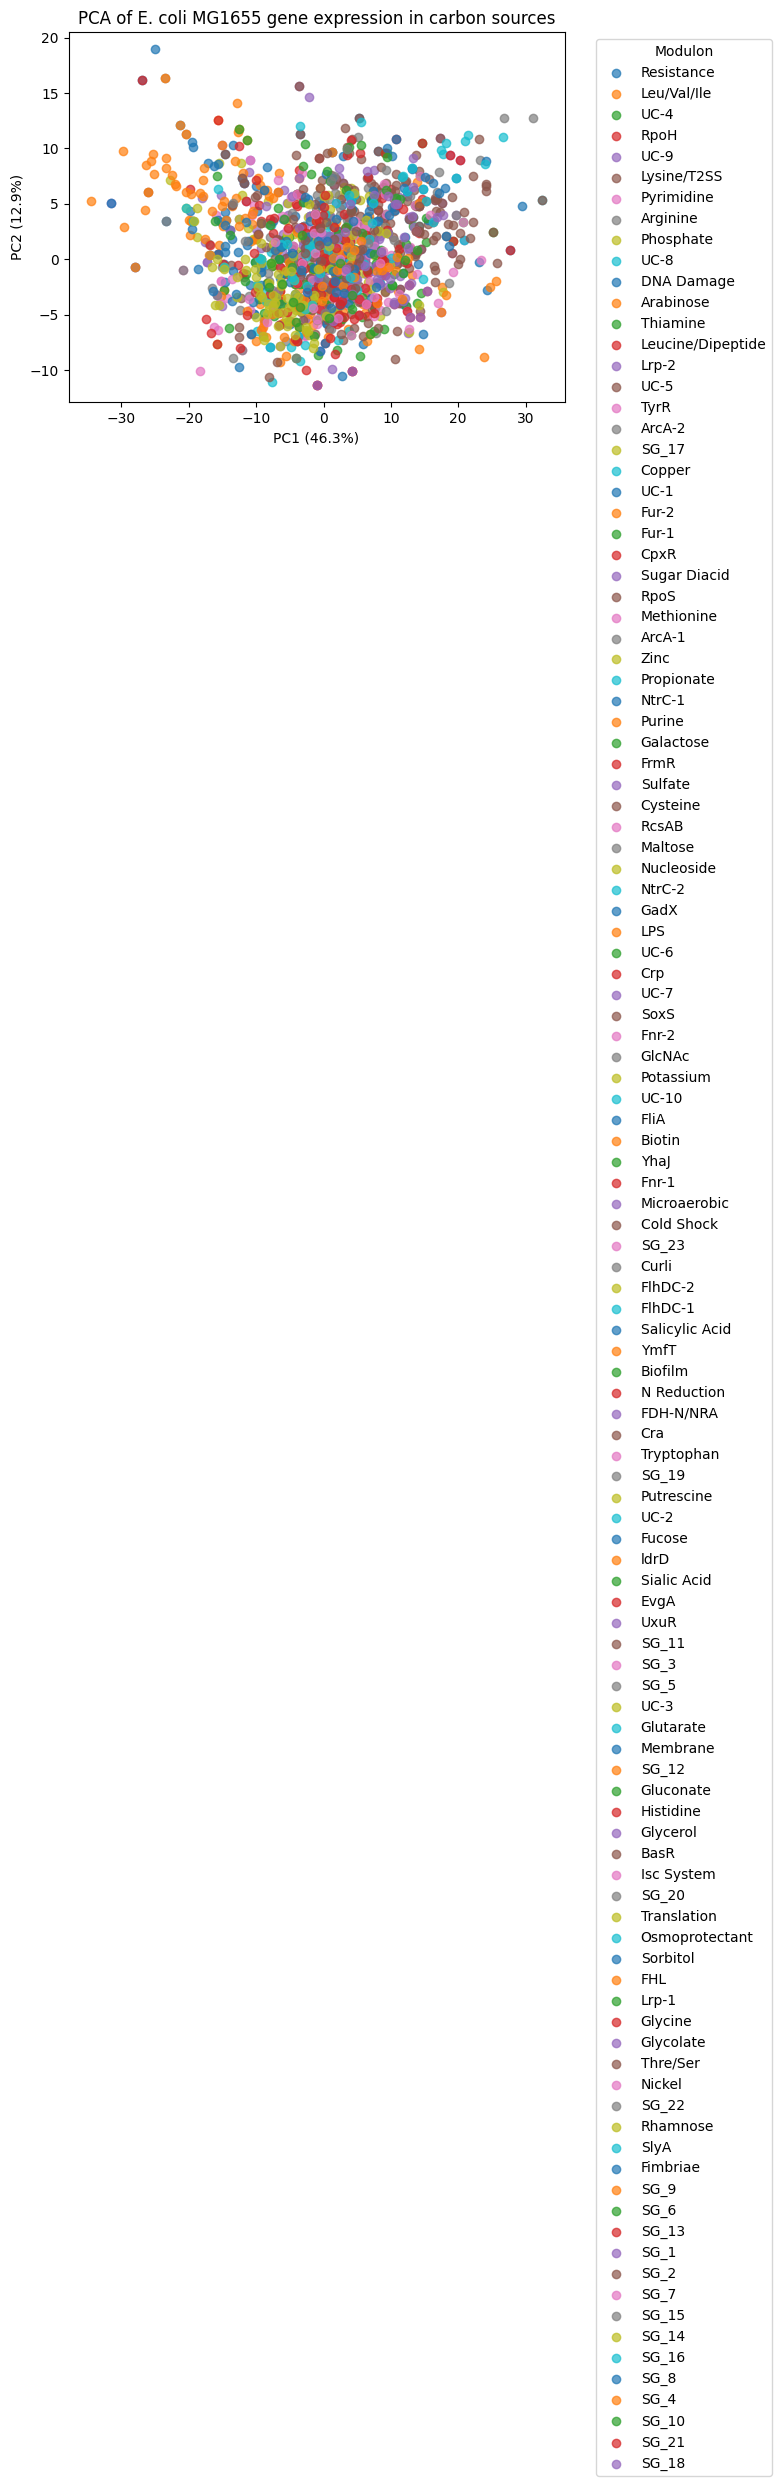

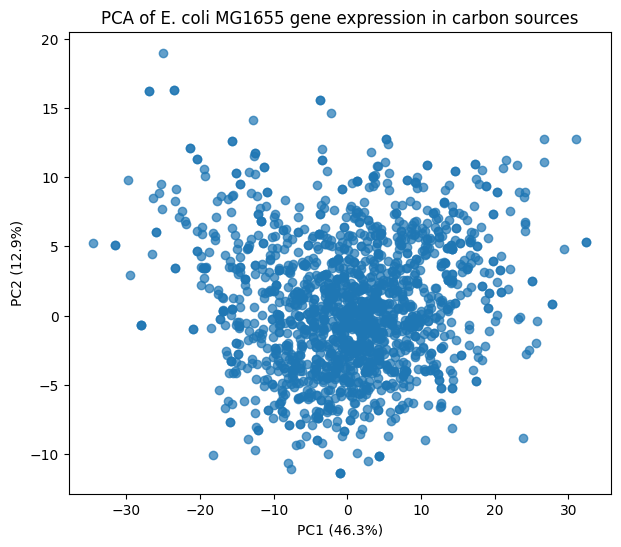

In [ ]:
for modulon in pca_df['modulon'].unique():
    subset = pca_df[pca_df['modulon'] == modulon]
    plt.scatter(
        subset.loc[:, "PC1"],
        subset.loc[:, "PC2"],
        alpha=0.7,
        label=modulon
    )
plt.legend(title="Modulon", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of E. coli MG1655 gene expression in carbon sources")
plt.show()

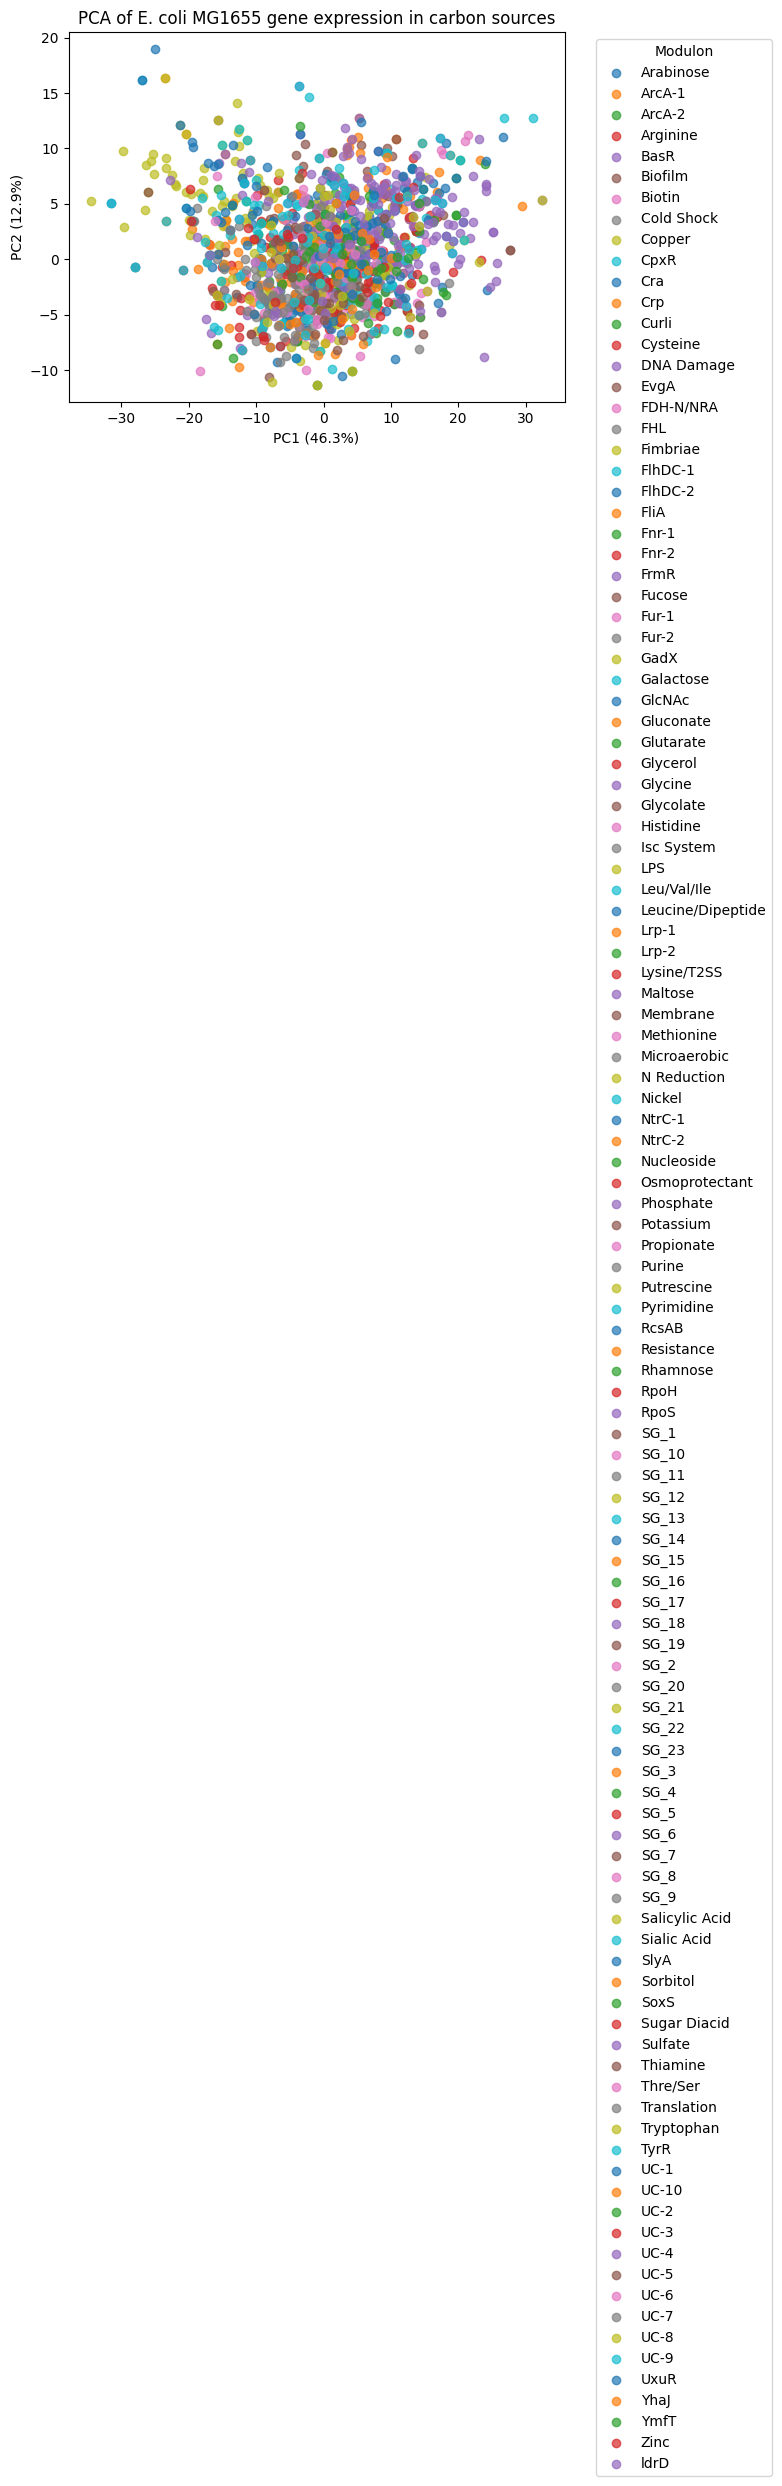

In [81]:
for modulon,gene_id in pca_df.groupby('modulon'):
    subset = pca_df[pca_df['modulon'] == modulon]
    plt.scatter(
        subset.loc[:, "PC1"],
        subset.loc[:, "PC2"],
        alpha=0.7,
        label=modulon
    )
plt.legend(title="Modulon", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of E. coli MG1655 gene expression in carbon sources")
plt.show()

In [51]:
carbon_tpm_T = carbon_tpm.T
carbon_tpm_T = carbon_tpm_T.rename(columns=carbon_tpm_T.iloc[0]).drop(carbon_tpm_T.index[0])
carbon_tpm_T.head()

,b0001,b0002,b0003,b0004,b0005,b0006,b0007,b0008,b0009,b0010,...,b4815,b4816,b4817,b4818,b4819,b4820,b4821,b4822,b4823,b4824
pmg_wt_100,0.722802,-0.82217,0.091438,-0.045651,-0.470824,-0.340454,2.796091,1.365931,1.201413,1.036406,...,0.0,0.0,1.577454,-3.130411,2.208604,0.0,-2.174971,3.155315,2.046412,0.879156
pmg_wt_107,1.090242,-0.95581,-0.803884,-0.741174,-0.298003,-0.041867,0.16476,0.637574,1.10196,1.176421,...,0.0,0.0,0.353045,-2.928465,3.009361,0.0,-2.379444,1.339832,0.0,-1.98112
pmg_wt_108,1.130414,-1.223776,-1.207059,-0.888425,-0.370604,-0.11974,0.001251,0.717007,1.135318,1.654336,...,0.0,2.034534,0.417166,-4.271608,2.493943,0.0,-2.595892,2.09082,0.0,-1.98112
pmg_wt_125,1.860347,-1.001151,-0.791466,-0.78865,-0.683099,-0.330658,0.506842,0.571783,1.283853,1.358169,...,0.0,1.234556,0.683945,-4.899494,2.848388,0.0,-3.152453,1.277571,0.0,-1.98112
pmg_wt_126,2.260856,-1.001738,-0.815086,-0.796482,-0.937261,-0.262284,0.39553,0.573658,1.275763,1.33566,...,0.0,0.99111,0.329893,-4.196615,3.555638,0.0,-3.034748,2.367033,0.0,0.120657


In [129]:
#do PC1 with PC3


X = carbon_tpm.set_index("gene_id")
print (X.shape)  # (82, 4140)
print (X.head())

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X)

(4305, 82)
         pmg_wt_100  pmg_wt_107  pmg_wt_108  pmg_wt_125  pmg_wt_126  \
gene_id                                                               
b0001      0.722802    1.090242    1.130414    1.860347    2.260856   
b0002     -0.822170   -0.955810   -1.223776   -1.001151   -1.001738   
b0003      0.091438   -0.803884   -1.207059   -0.791466   -0.815086   
b0004     -0.045651   -0.741174   -0.888425   -0.788650   -0.796482   
b0005     -0.470824   -0.298003   -0.370604   -0.683099   -0.937261   

         pmg_wt_141  pmg_wt_142  pmg_wt_143  pmg_wt_144  pmg_wt_27  ...  \
gene_id                                                             ...   
b0001     -0.990012   -0.877302    1.217422    1.288113   0.120906  ...   
b0002     -0.276547   -0.114908   -0.452704   -0.855671   0.071964  ...   
b0003      0.420163    0.490753   -0.188748   -0.720093   0.499889  ...   
b0004      0.267219    0.346992   -0.119051   -0.609777   0.693013  ...   
b0005     -0.473663   -1.197339   -0.5628

In [96]:
pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=[f"PC{i+1}" for i in range(X_pca.shape[1])]
)

pca_df.head()

,PC1,PC2,PC3
gene_id,,,
b0001,-2.412352,-6.649372,-0.649716
b0002,-9.484135,-4.033864,2.137095
b0003,-5.998332,-5.790094,1.282602
b0004,-6.274273,-5.888527,0.494857
b0005,-7.262729,-4.664172,-0.274450


In [98]:
pca_df=pca_df.merge(
    gene_modulon_long,
    left_index = True,
    right_on = "gene_id"
)

pca_df.head()

,PC1,PC2,PC3,gene_id,modulon
0,-2.412352,-6.649372,-0.649716,b0001,Resistance
1,-9.484135,-4.033864,2.137095,b0002,Leu/Val/Ile
2,-5.998332,-5.790094,1.282602,b0003,Leu/Val/Ile
3,-6.274273,-5.888527,0.494857,b0004,Leu/Val/Ile
4,-7.262729,-4.664172,-0.274450,b0005,UC-4


In [ ]:
pca_df.to_csv('pca_df.csv', index=False)
#the double entries do not affect the PC values

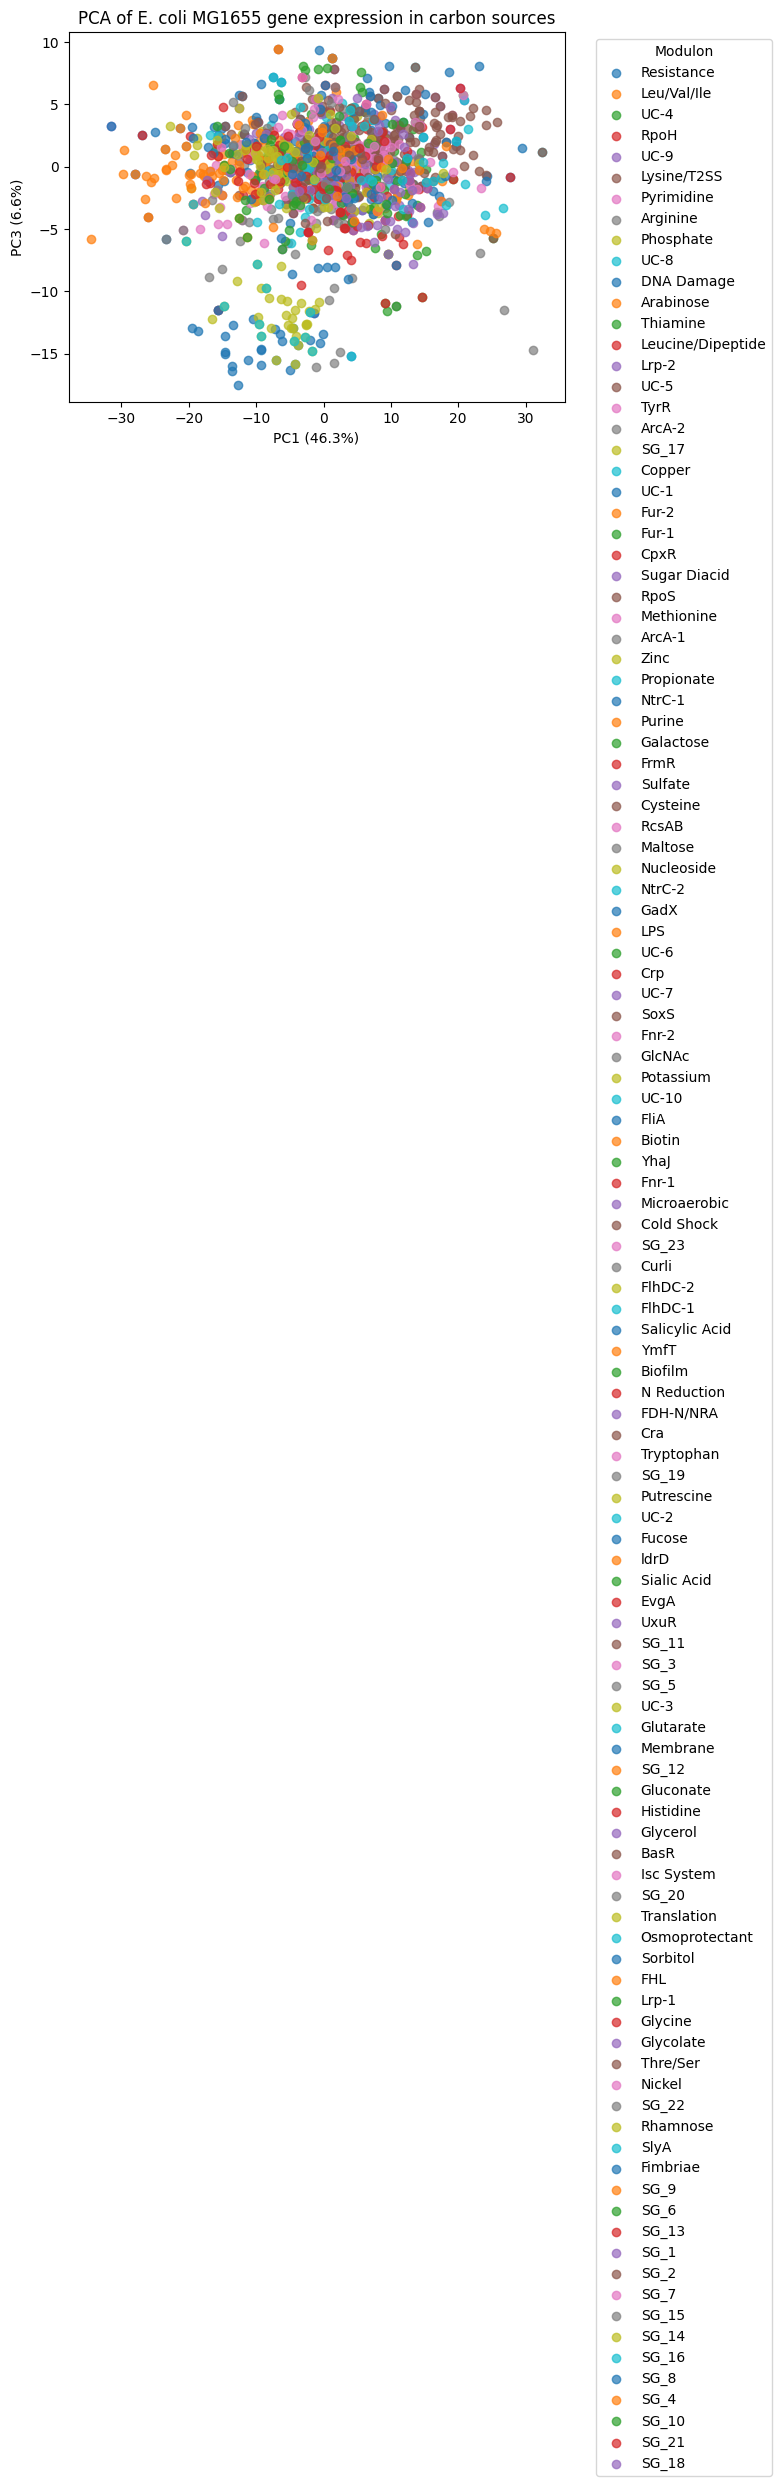

In [99]:
for modulon in pca_df['modulon'].unique():
    subset = pca_df[pca_df['modulon'] == modulon]
    plt.scatter(
        subset.loc[:, "PC1"],
        subset.loc[:, "PC3"],
        alpha=0.7,
        label=modulon
    )
plt.legend(title="Modulon", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)")
plt.title("PCA of E. coli MG1655 gene expression in carbon sources")
plt.show()

In [ ]:
#find the duplicate genes - so it means that the same gene is involved in multiple modulons

duplicate_genes = gene_modulon_long[gene_modulon_long.duplicated(subset=['gene_id'], keep=False)] #keep 
duplicate_genes.head()
duplicate_genes.to_csv('duplicate_genes.csv', index=False)
duplicate_genes.size

1096

c:\Users\eleva\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


ValueError: The condensed distance matrix must contain only finite values.

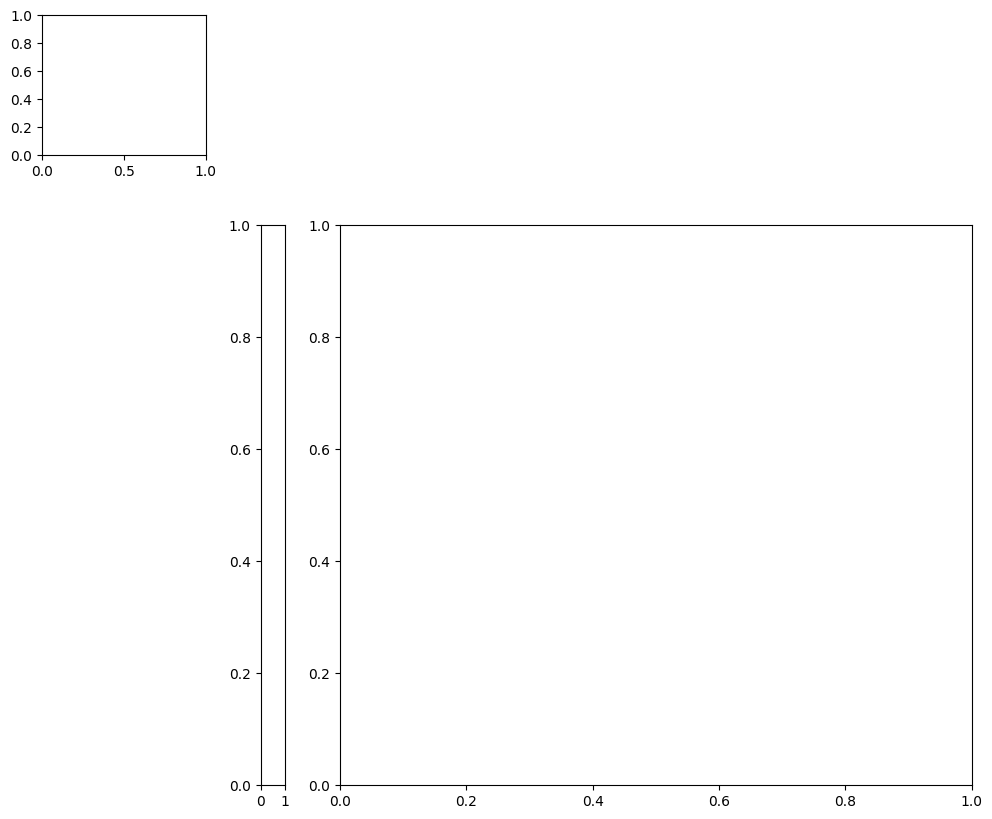

In [114]:
#create hitmaps 

import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

expression = carbon_tpm

#standardize each gene across samples 

expression = expression.apply(pd.to_numeric, errors="coerce")

# expression = StandardScaler().fit_transform(expression.set_index('gene_id')) #this standardizes the columns but we need the rows 

# expression_scaled = pd.DataFrame(
#     StandardScaler().fit_transform(expression.T).T,
#     index=expression.index,
#     columns=expression.columns
# )

expression_scaled = expression.sub(
    expression.mean(axis=1), axis=0
).div(
    expression.std(axis=1).replace(0, 1), axis=0
)
#choose one modulon per gene for the annotation 

gene_to_modulon = (
    gene_modulon_long
    .drop_duplicates(subset="gene_id", keep="first")
    .set_index("gene_id")["modulon"]
)

#match modulon labels to expression matrix rows
row_modulon = gene_to_modulon.reindex(expression_scaled.index).fillna("Unassigned")

# Color strip for the modulon annotation
modulon_codes = pd.Categorical(row_modulon)
palette = dict(zip(
    modulon_codes.categories,
    sns.color_palette("husl", len(modulon_codes.categories))
))
row_colors = row_modulon.map(palette)

# Draw heatmap
sns.clustermap(
    expression_scaled,
    row_colors=row_colors,
    cmap="vlag",
    center=0,
    xticklabels=False,
    yticklabels=False,
    figsize=(12, 10)
)

plt.show()

c:\Users\eleva\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\Users\eleva\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


NameError: name 'Patch' is not defined

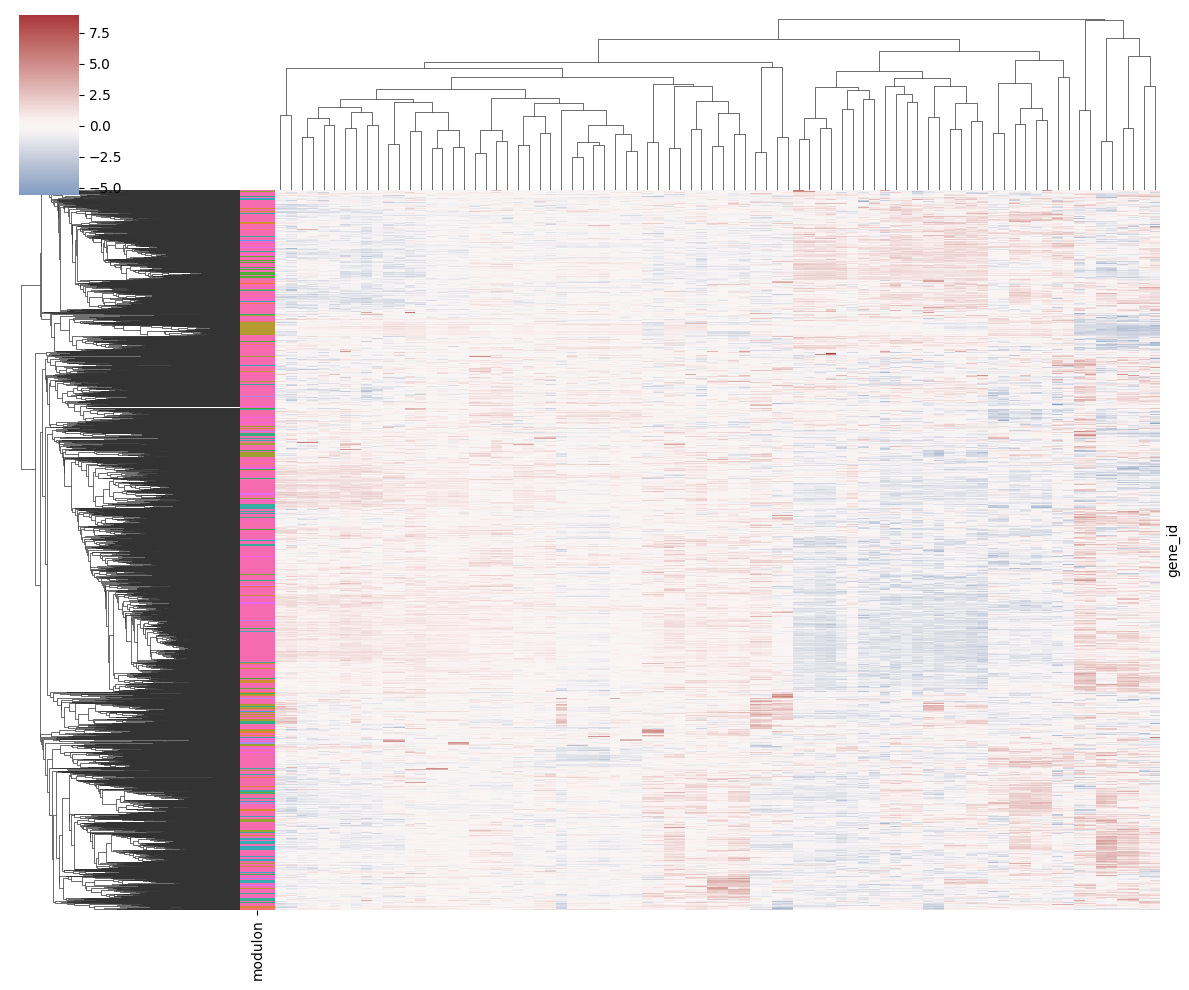

In [123]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Transpose: genes become rows, samples become columns
expression = carbon_tpm.set_index("gene_id")

# expression = expression.iloc[:, 1:]  # Exclude the gene_id column for standardization

# Standardize each gene across samples
expression_z = expression.sub(
    expression.mean(axis=1), axis=0
).div(
    expression.std(axis=1).replace(0, 1), axis=0
)

# Choose one modulon per gene for this simple annotation
gene_to_modulon = (
    gene_modulon_long
    .drop_duplicates("gene_id")
    .set_index("gene_id")["modulon"]
)

# Match modulon labels to expression matrix rows
row_modulon = gene_to_modulon.reindex(expression_z.index).fillna("Unassigned")

# Color strip for the modulon annotation
modulon_codes = pd.Categorical(row_modulon)
palette = dict(zip(
    modulon_codes.categories,
    sns.color_palette("husl", len(modulon_codes.categories))
))
row_colors = row_modulon.map(palette)

# Draw heatmap
sns.clustermap(
    expression_z,
    row_colors=row_colors,
    cmap="vlag",
    center=0,
    xticklabels=False,
    yticklabels=False,
    figsize=(12, 10)
)


#create a legnet for modulon colors

handles = [
    Patch(facecolor=color, label=modulon)
    for modulon, color in palette.items()
]

g.ax_heatmap.legend(
    handles=handles,
    title="Modulon",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.show()

In [126]:
# create a PCA plot with the modoulons (representing the average of gene expression) as dots

modulon_avg_expression = (
    expression_z
    .join(gene_to_modulon, how="left")
    .groupby("modulon")
    .mean()
)

modulon_avg_expression.head()

,pmg_wt_100,pmg_wt_107,pmg_wt_108,pmg_wt_125,pmg_wt_126,pmg_wt_141,pmg_wt_142,pmg_wt_143,pmg_wt_144,pmg_wt_27,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
modulon,,,,,,,,,,,,,,,,,,,,,
Arabinose,-0.354226,-0.151716,-0.415853,-0.125458,-0.202609,-0.413790,-0.229038,-0.148422,-0.239919,4.032020,...,-0.374684,0.293660,0.076398,0.742686,0.587323,0.595121,0.553019,-0.015092,0.244160,-0.477068
ArcA-1,-1.323364,0.352975,0.094152,0.475016,0.441077,-1.343201,-1.468425,-0.291931,-1.499387,-0.804417,...,-0.112043,0.413436,0.417350,0.890123,0.932343,-0.126142,-0.256347,0.559539,0.618711,-1.401113
ArcA-2,-0.505771,-0.149823,-0.235594,0.013324,-0.075043,-1.939231,-2.120057,0.031740,-1.595856,0.448321,...,0.166712,0.273053,0.285569,0.019250,-0.178081,0.264032,0.237150,0.412451,0.448205,-0.363796
Arginine,-0.840641,-0.352727,-0.288477,0.065382,-0.086436,0.782368,0.531502,0.027172,-0.837450,0.623678,...,-0.567182,0.205389,0.245871,0.196935,-0.032520,-0.048149,-0.033099,1.359580,1.300596,-0.625839
BasR,-0.635616,0.665459,0.674982,-0.032903,0.077152,0.058006,0.026731,-0.320705,-0.591879,-0.509486,...,0.557752,-0.890541,-0.545379,0.097753,-0.005388,0.222966,0.298095,-0.261188,-0.474293,-0.722160


In [132]:
X = modulon_avg_expression
print (X.shape)  # (82, 4140)
print (X.head())

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

(112, 82)
           pmg_wt_100  pmg_wt_107  pmg_wt_108  pmg_wt_125  pmg_wt_126  \
modulon                                                                 
Arabinose   -0.354226   -0.151716   -0.415853   -0.125458   -0.202609   
ArcA-1      -1.323364    0.352975    0.094152    0.475016    0.441077   
ArcA-2      -0.505771   -0.149823   -0.235594    0.013324   -0.075043   
Arginine    -0.840641   -0.352727   -0.288477    0.065382   -0.086436   
BasR        -0.635616    0.665459    0.674982   -0.032903    0.077152   

           pmg_wt_141  pmg_wt_142  pmg_wt_143  pmg_wt_144  pmg_wt_27  ...  \
modulon                                                               ...   
Arabinose   -0.413790   -0.229038   -0.148422   -0.239919   4.032020  ...   
ArcA-1      -1.343201   -1.468425   -0.291931   -1.499387  -0.804417  ...   
ArcA-2      -1.939231   -2.120057    0.031740   -1.595856   0.448321  ...   
Arginine     0.782368    0.531502    0.027172   -0.837450   0.623678  ...   
BasR         0.0

In [133]:
pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=[f"PC{i+1}" for i in range(X_pca.shape[1])]
)

pca_df.head()

,PC1,PC2
modulon,,
Arabinose,1.032861,-1.800677
ArcA-1,4.012702,-2.879616
ArcA-2,-1.625335,-1.652207
Arginine,-4.736549,0.518063
BasR,3.945808,-1.328308


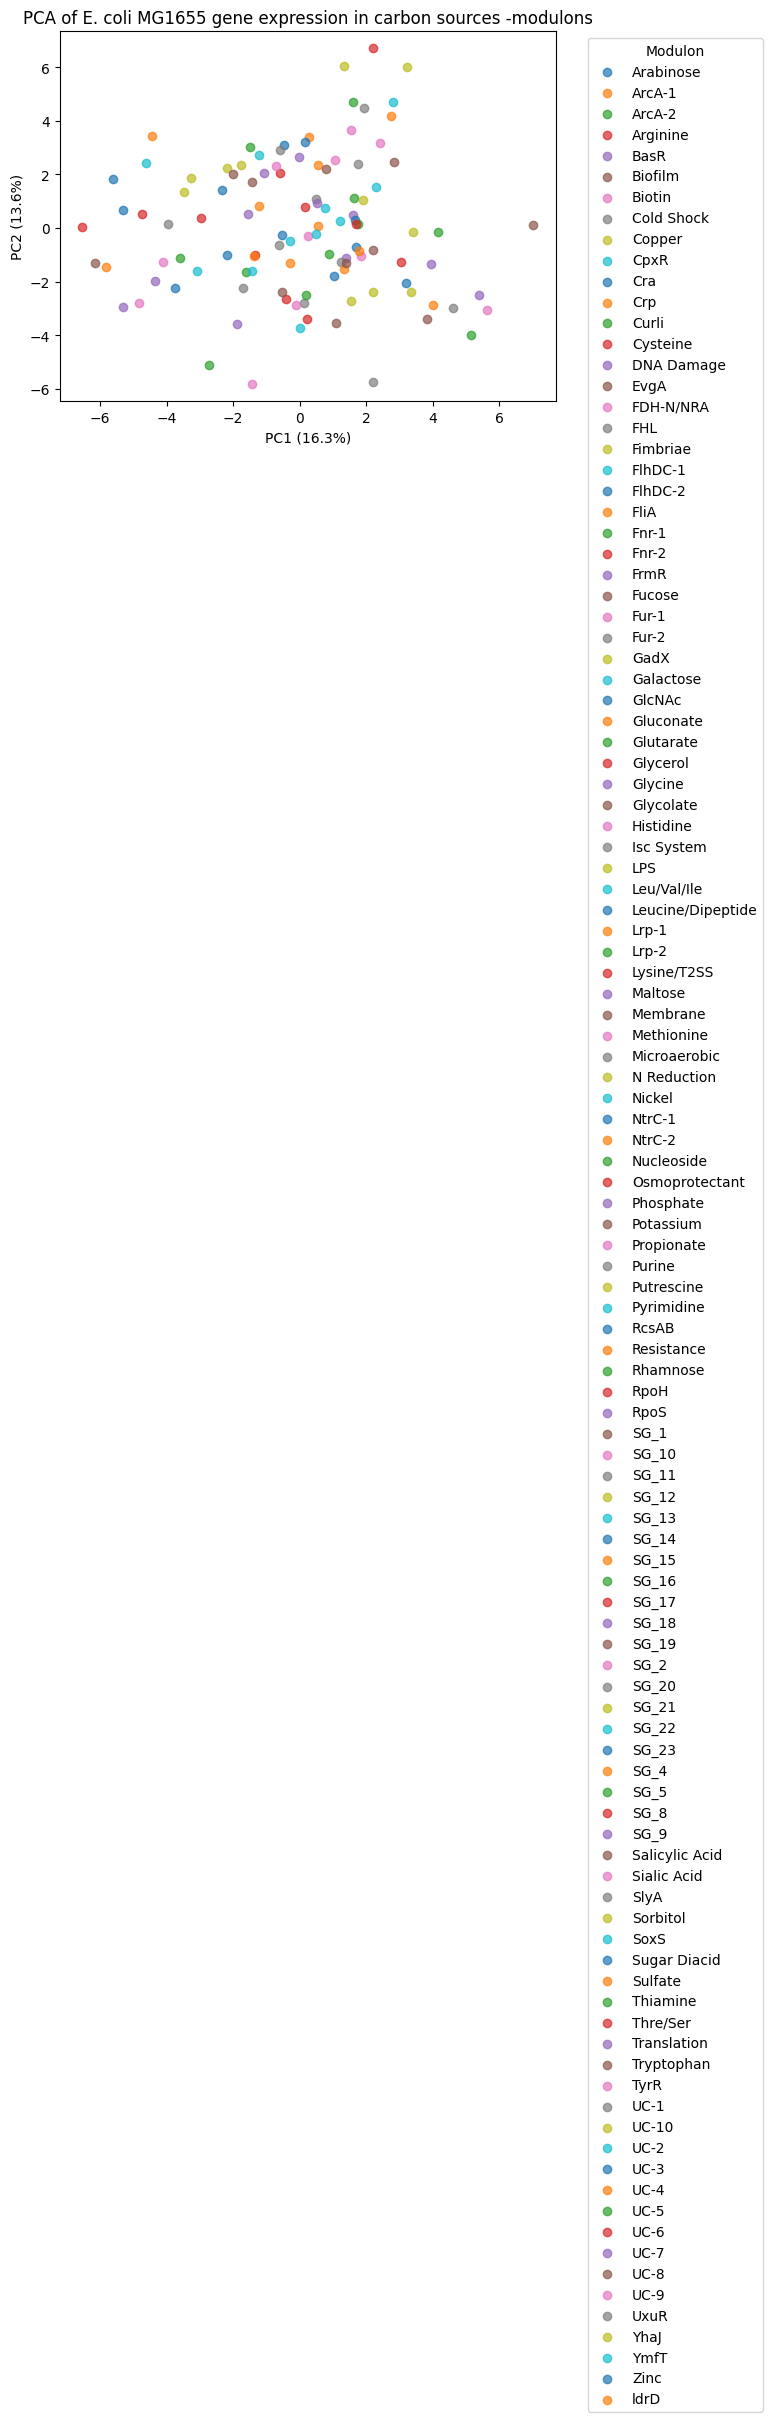

In [ ]:
#now at this plot 
for modulon in pca_df.index:
    subset = pca_df[pca_df.index == modulon]
    plt.scatter(
        subset.loc[:, "PC1"],
        subset.loc[:, "PC2"],
        alpha=0.7,
        label=modulon
    )
plt.legend(title="Modulon", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of E. coli MG1655 gene expression in carbon sources -modulons")
plt.show()

In [140]:
#we can observe that one modulon is isolated 

isolated_modulon = pca_df[pca_df['PC1'] > 6]  # Example condition to identify isolated modulons
print (isolated_modulon)

              PC1       PC2
modulon                    
Biofilm  7.018316  0.120796


In [141]:
print (modulon_dict['Biofilm'])

{'b1165', 'b1164', 'b1166', 'b1167'}


In [153]:
three_clustered = pca_df[(pca_df['PC1'] >=1.5 ) & (pca_df['PC1'] <=3 ) &(pca_df['PC2'] >=-2) & (pca_df['PC2'] <=0) ]
print (three_clustered)

                   PC1       PC2
modulon                         
Fucose        2.195804 -0.810222
Sialic Acid   1.826478 -1.055209
Sugar Diacid  1.704161 -0.703177
UC-4          1.794447 -0.874541


In [152]:
pca_df.to_csv('pca_df_modulons.csv', index=False)

In [157]:
common_genes = set(modulon_dict['Sugar Diacid']).intersection(set(modulon_dict['Sialic Acid'])).intersection(set(modulon_dict['UC-4']))
print (common_genes)

set()


In [ ]:
common_genes_sugar_sialic = set(modulon_dict['Sugar Diacid']).intersection(set(modulon_dict['Sialic Acid']))
common_genes_sugar_sialic

set()

In [163]:
common_genes_sugar_uc4 = set(modulon_dict['Sugar Diacid']).intersection(set(modulon_dict['UC-4']))
common_genes_sugar_uc4

set()

In [164]:
common_genes_sialic_uc4 = set(modulon_dict['Sialic Acid']).intersection(set(modulon_dict['UC-4']))
common_genes_sialic_uc4

set()

In [185]:
print ('\n Sugar Diacid:',modulon_dict['Sugar Diacid'], '\n Sialic Acid:',modulon_dict['Sialic Acid'], '\n UC-4:', modulon_dict['UC-4'])


 Sugar Diacid: {'b0162', 'b2789', 'b2788', 'b2787', 'b3126', 'b3127', 'b3125', 'b3128', 'b3124'} 
 Sialic Acid: {'b4311', 'b4310', 'b3223', 'b4309', 'b3221', 'b3224', 'b3222', 'b4655', 'b4279', 'b4280', 'b1596', 'b3225', 'b1498'} 
 UC-4: {'b1110', 'b2390', 'b1379', 'b0379', 'b2838', 'b4050', 'b0005', 'b2466', 'b2018', 'b1283', 'b1743', 'b1481'}


In [175]:
cluster_genes = list(set(modulon_dict['Sugar Diacid']).union(set(modulon_dict['Sialic Acid'])).union(set(modulon_dict['UC-4'])))
cluster_genes


['b0162',
 'b4310',
 'b1379',
 'b0379',
 'b2838',
 'b3126',
 'b3222',
 'b0005',
 'b1283',
 'b4279',
 'b4309',
 'b3127',
 'b4280',
 'b3128',
 'b1498',
 'b4311',
 'b1110',
 'b2390',
 'b2788',
 'b3124',
 'b3223',
 'b3221',
 'b3224',
 'b2787',
 'b4050',
 'b2466',
 'b2018',
 'b4655',
 'b1743',
 'b1481',
 'b3125',
 'b1596',
 'b3225',
 'b2789']

In [170]:
gene_info = pd.read_csv('precise_mg1655-gene_info.csv')
gene_info_dict = dict(zip(gene_info["gene_id"], gene_info["cog"]))
gene_info_dict

{'b0001': 'No COG annotation',
 'b0002': 'Amino acid transport and metabolism',
 'b0003': 'Nucleotide transport and metabolism',
 'b0004': 'Amino acid transport and metabolism',
 'b0005': 'Function unknown',
 'b0006': 'Function unknown',
 'b0007': 'Amino acid transport and metabolism',
 'b0008': 'Carbohydrate transport and metabolism',
 'b0009': 'Nucleotide transport and metabolism',
 'b0010': 'Function unknown',
 'b0011': 'Function unknown',
 'b0012': 'No COG annotation',
 'b0013': 'Function unknown',
 'b0014': 'Post-translational modification, protein turnover, and chaperones',
 'b0015': 'Post-translational modification, protein turnover, and chaperones',
 'b0016': 'Replication, recombination and repair',
 'b0018': 'Function unknown',
 'b0019': 'Inorganic ion transport and metabolism',
 'b0020': 'Transcription',
 'b0021': 'Replication, recombination and repair',
 'b0022': 'Replication, recombination and repair',
 'b0023': 'Translation, ribosomal structure and biogenesis',
 'b0024': '

In [179]:
cluster_genes_cog = {
    gene: gene_info_dict.get(gene, "Unknown")
    for gene in cluster_genes
}

cluster_genes_cog

{'b0162': 'Transcription',
 'b4310': 'Cell wall\\/membrane\\/envelope biogenesis',
 'b1379': 'Post-translational modification, protein turnover, and chaperones',
 'b0379': 'Function unknown',
 'b2838': 'Amino acid transport and metabolism',
 'b3126': 'Carbohydrate transport and metabolism',
 'b3222': 'Nucleotide transport and metabolism',
 'b0005': 'Function unknown',
 'b1283': 'Cell wall\\/membrane\\/envelope biogenesis',
 'b4279': 'Inorganic ion transport and metabolism',
 'b4309': 'Function unknown',
 'b3127': 'Inorganic ion transport and metabolism',
 'b4280': 'Function unknown',
 'b3128': 'Amino acid transport and metabolism',
 'b1498': 'Inorganic ion transport and metabolism',
 'b4311': 'Cell wall\\/membrane\\/envelope biogenesis',
 'b1110': 'Function unknown',
 'b2390': 'Function unknown',
 'b2788': 'Cell wall\\/membrane\\/envelope biogenesis',
 'b3124': 'Carbohydrate transport and metabolism',
 'b3223': 'Carbohydrate transport and metabolism',
 'b3221': 'Carbohydrate transport 

In [183]:
function_unknown = {
    gene: cog
    for gene, cog in cluster_genes_cog.items()
    if cog == "Function unknown"
}
function_unknown

{'b0379': 'Function unknown',
 'b0005': 'Function unknown',
 'b4309': 'Function unknown',
 'b4280': 'Function unknown',
 'b1110': 'Function unknown',
 'b2390': 'Function unknown',
 'b4050': 'Function unknown',
 'b2466': 'Function unknown',
 'b1481': 'Function unknown'}